# 00 · Project guide

How the analysis is organised and how to run it, with a short example of each code notebook.

```
Thesis_downoading_the_data/
├── requirements.txt        package versions
├── src/                    shared code, used by every analysis notebook
│   ├── setup.ipynb             loads the notebooks below, in this order
│   ├── config.ipynb            settings and the nine configurations (object `cfg`)
│   ├── data_utils.ipynb        the 216 patients; matrix and blocks of each configuration
│   ├── psi.ipynb               Pairwise Separability Index
│   ├── clustering_utils.ipynb  fitting a configuration; bootstrap refits
│   ├── evaluation_utils.ipynb  PSI tables, cluster numbering, medoids
│   └── plot_utils.ipynb        figures
├── analysis/               the analysis, one notebook per question
│   ├── 01_choose_k                number of clusters
│   ├── 02_compare_configurations  PSI of every configuration and selection
│   ├── 03_profile_selected        the selected clusters in detail
│   ├── 04_stability               stability of the partitions
│   ├── 05_secondary_results       silhouette and agreement with CDR
│   ├── 06_pca_robustness          number of image components
│   ├── 07_before_after            comparison with the previous method
│   └── 09_results                 summary of the results
├── results/                figures and tables, one folder per analysis notebook
└── notebooks/              data pipeline (HOG features, PCA) and earlier experiments
```

The `src/` notebooks only define settings and functions. Every analysis notebook loads them with its first line,
`%run -i ../src/setup.ipynb`, so all analyses use the same code. The analysis notebooks produce the results and
save them in `results/`.

The input data are the clinical spreadsheet and the five `pca_<type>.csv` files in
`notebooks/01_data_pipeline/`; notebook 06 also reads `raw_hog_features_per_image.csv` from there.

## How to run

1. Select the kernel *Python (thesis .venv)*.
2. Run the analysis notebooks in order. Notebook 02 has to run before 03–07, because they read its selection
   (`results/02_compare_configurations/selection.json`).
3. To set up the environment on another computer: `pip install --no-deps -r requirements.txt` (the reason for
   `--no-deps` is explained in that file).

In [1]:
%run -i ../src/setup.ipynb
import inspect
from importlib.metadata import version
import sys

print("Python", sys.version.split()[0])
for p in ["robust-mixed-dist", "db-robust-clust", "kmedoids", "scikit-learn", "numpy", "pandas"]:
    print(f"{p:18s} {version(p)}")

Python 3.12.10
robust-mixed-dist  0.1.31
db-robust-clust    0.1.15
kmedoids           0.5.5
scikit-learn       1.9.1
numpy              1.26.4
pandas             3.0.6


## 1. Configurations

The table is generated from `cfg.CONFIGS`, so it always matches the code.

In [2]:
rows = []
for name, c in cfg.CONFIGS.items():
    if c["algorithm"] == "kmeans":
        parts = []
        if c.get("kmeans_standardise"):
            parts.append("standardised " + ", ".join(c["kmeans_standardise"]))
        if c.get("kmeans_onehot"):
            parts.append("one-hot " + ", ".join(c["kmeans_onehot"]))
        if c.get("kmeans_raw"):
            parts.append("550 image PCs")
        blocks, method = " + ".join(parts) + " (Euclidean)", "k-means"
    else:
        blocks = " + ".join(f"{label} ({dist})" for label, _, dist in c["quant_blocks"])
        if c.get("multiclass"):
            blocks += " + multiclass " + ", ".join(c["multiclass"]) + " (hamming)"
        method = c["metric"] or "best of M1/M2 (set in 02)"
    rows.append({"ID": name, "feature space": c["feature_space"], "method": method,
                 "blocks (distance)": blocks, "tests": c["description"]})
pd.set_option("display.max_colwidth", 200)
print("k =", cfg.K, "| clinical quantitative:", cfg.CLINICAL_QUANT, "| multiclass:", cfg.CLINICAL_MULTICLASS)
pd.DataFrame(rows).set_index("ID")

k = 4 | clinical quantitative: ['Age', 'MMSE', 'eTIV', 'nWBV'] | multiclass: ['Educ', 'SES', 'sex']


,feature space,method,blocks (distance),tests
ID,,,,
C1,Clinical,ggower,"clinical (robust_mahalanobis) + multiclass Educ, SES, sex (hamming)",Clinical baseline
C1-b,Clinical,k-means,"standardised Age, MMSE, eTIV, nWBV + one-hot Educ, SES, sex (Euclidean)",Effect of the algorithm on the same features
C2,Clinical + CDR,ggower,"clinical+CDR (robust_mahalanobis) + multiclass Educ, SES, sex (hamming)",Severity as part of the profile
I1,Images,relms,cor (euclidean) + gfc_sag (euclidean) + gfc_tra (euclidean) + masked_tra (euclidean) + sbj_sag (euclidean),Image-only structure
I2,Images,ggower,cor (euclidean) + gfc_sag (euclidean) + gfc_tra (euclidean) + masked_tra (euclidean) + sbj_sag (euclidean),RelMS vs. G-Gower on images
I2-b,Images,k-means,550 image PCs (Euclidean),Effect of the algorithm on images
M1,Images + clinical,relms,"cor (euclidean) + gfc_sag (euclidean) + gfc_tra (euclidean) + masked_tra (euclidean) + sbj_sag (euclidean) + clinical (robust_mahalanobis) + multiclass Educ, SES, sex (hamming)",Added value of images
M2,Images + clinical,ggower,"cor (euclidean) + gfc_sag (euclidean) + gfc_tra (euclidean) + masked_tra (euclidean) + sbj_sag (euclidean) + clinical (robust_mahalanobis) + multiclass Educ, SES, sex (hamming)","Same, with G-Gower"
M3,Images + clinical + CDR,best of M1/M2 (set in 02),"cor (euclidean) + gfc_sag (euclidean) + gfc_tra (euclidean) + masked_tra (euclidean) + sbj_sag (euclidean) + clinical+CDR (robust_mahalanobis) + multiclass Educ, SES, sex (hamming)",Full profile including severity


## 2. The analysis sample

In [3]:
df = load_analysis_data()
print("patients:", len(df), "| sex:", df["M/F"].value_counts().to_dict(), "| CDR:", df["CDR"].value_counts().sort_index().to_dict())
d = build_design(df, cfg.CONFIGS["M1"])
print("\nM1 matrix:", d["X"].shape)
print("blocks:", d["block_labels"])
print("p1 (columns per block):", d["p1"])
print("d1 (distance per block):", d["d1"])

patients: 216 | sex: {'F': 145, 'M': 71} | CDR: {0.0: 133, 0.5: 57, 1.0: 24, 2.0: 2}

M1 matrix: (216, 557)
blocks: ['cor', 'gfc_sag', 'gfc_tra', 'masked_tra', 'sbj_sag', 'clinical', 'multiclass']
p1 (columns per block): [110, 110, 110, 110, 110, 4]
d1 (distance per block): ['euclidean', 'euclidean', 'euclidean', 'euclidean', 'euclidean', 'robust_mahalanobis']


## 3. Pairwise Separability Index

In [4]:
print("Cliff's delta, A always higher than B:", cliffs_delta(np.array([5, 6, 7]), np.array([1, 2, 3])))
print("Cliff's delta, same values           :", cliffs_delta(np.array([1, 2, 3]), np.array([1, 2, 3])))
toy = pd.DataFrame({"cluster": [0] * 10 + [1] * 10, "sex": ["F"] * 8 + ["M"] * 2 + ["F"] * 3 + ["M"] * 7})
print("TVD, 80% vs 30% women                :",
      compute_config_pairwise_separability(toy, "cluster", [], ["sex"], "toy").pairwise_separability_index)

Cliff's delta, A always higher than B: 1.0
Cliff's delta, same values           : 0.0
TVD, 80% vs 30% women                : 0.5


## 4. Fitting a configuration

C1 at k = 4. Its distance has two blocks of equal weight: the quantitative clinical variables (Age, MMSE, eTIV,
nWBV, robust Mahalanobis) and the multiclass block (Education, SES and sex, Hamming). The table shows how many men
and women end up in each cluster.

In [5]:
r = fit_configuration("C1", cfg.K, df)
d = build_design(df, cfg.CONFIGS["C1"])
print("blocks:", d["block_labels"], "| p1:", d["p1"], "| p3 (multiclass):", d["p3"])
print("C1, k = 4: cluster sizes", np.bincount(r["labels"]).tolist())
pd.crosstab(relabel_by(df, r["labels"], "MMSE"), df["M/F"]).rename_axis("cluster")

blocks: ['clinical', 'multiclass'] | p1: 4 | p3 (multiclass): 3
C1, k = 4: cluster sizes [76, 64, 41, 35]


M/F,F,M
cluster,,
1,36,5
2,16,48
3,65,11
4,28,7


## 5. PSI table and medoids

In [6]:
labels = relabel_by(df, r["labels"], "MMSE")
display(format_psi_table(psi_column(df, labels, "C1").to_frame()))
medoid_table(df, labels, r["medoids"])

,C1
Age,0.265 (S)
MMSE,0.373 (M)
nWBV,0.445 (M)
eTIV,0.451 (M)
CDR,0.346 (M)
Educ,0.593 (L)
SES,0.674 (L)
sex,0.323 (S)
PSI (mean),0.434 (M)


,cluster,n,medoid,sex,Age,MMSE,CDR,nWBV,eTIV,Educ,SES
0,1,41,OAS1_0109,F,61,30.0,0.0,0.813,1313,4.0,3.0
1,2,64,OAS1_0256,M,70,30.0,0.0,0.739,1660,5.0,1.0
2,3,76,OAS1_0237,F,72,27.0,0.0,0.764,1322,2.0,2.0
3,4,35,OAS1_0425,F,78,23.0,1.0,0.715,1461,1.0,4.0


## 6. Cluster profile figure

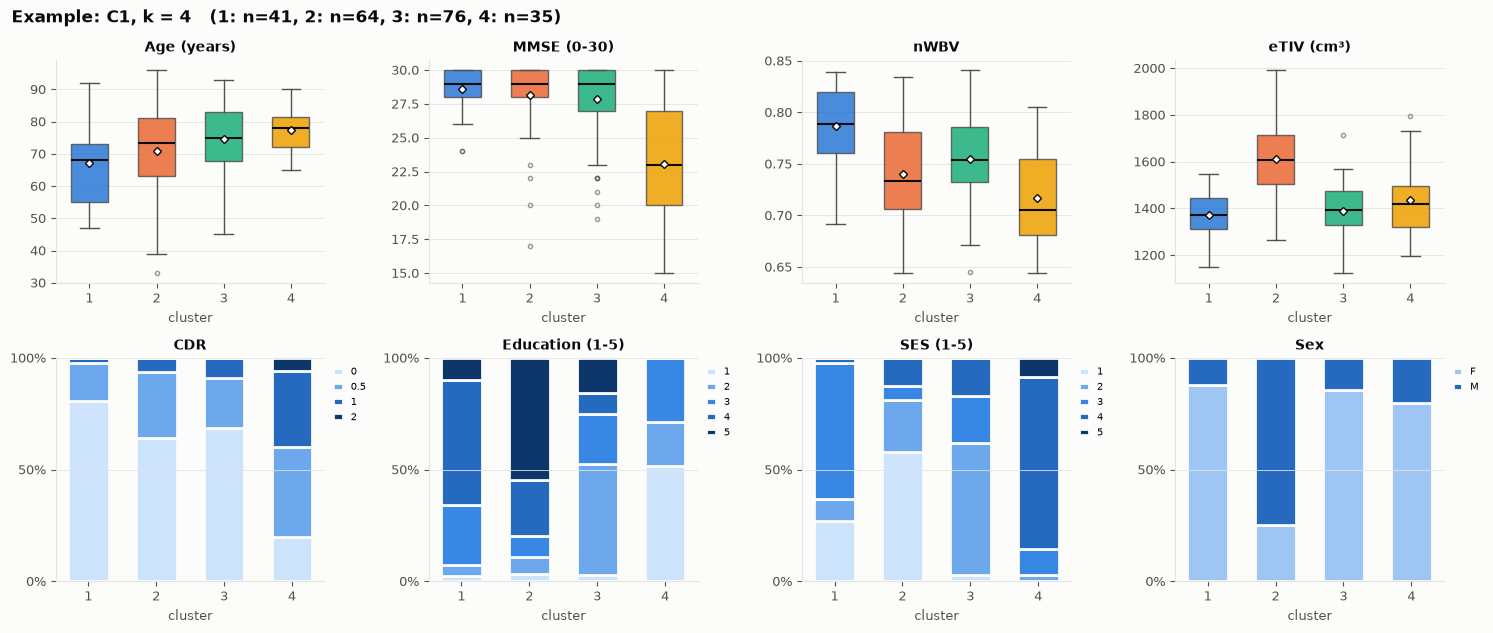

In [7]:
fig = cluster_profile(df, labels, "Example: C1, k = 4")
plt.show()